### Importing necessary libraries

In [1]:
# %pip install pandas, numpy, seaborn, matplotlib, pillow, tqdm, scikit-learn, catboost
# %pip install -U ipywidgets

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import PIL.Image as Image
import os, random, time
import math
from catboost import CatBoostClassifier, CatBoostRegressor
import tqdm
from tqdm.auto import tqdm

from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import LabelEncoder, OrdinalEncoder, OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from scipy.stats import chi2_contingency

In [3]:
SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)

pd.set_option('display.max_columns', None)
# colors = ["#078533", "#850728", "#fcba03"]
sns.set_palette(sns.color_palette("Set2"))

### Read dataset

In [4]:
DATA_PATH = [
                "./data/raw/1_differentiated_thyroid_cancer_recurrence.csv",
                "./data/raw/2_cirrhosis_patient_survival_prediction.csv",
                "./data/raw/3_glioma_grading_clinical_and_mutation_features.csv",
                "./data/raw/5_beed_bangalore_eeg_epilepsy_dataset",
                "./data/raw/6_cdc_diabetes_health_indicators"
]

# DATA_PATH = "./data/raw/2_cirrhosis_patient_survival_prediction.csv"

df = pd.read_csv(DATA_PATH[2])
df_raw = df.copy()
print("Data frame shape:", df.shape)

Data frame shape: (839, 24)


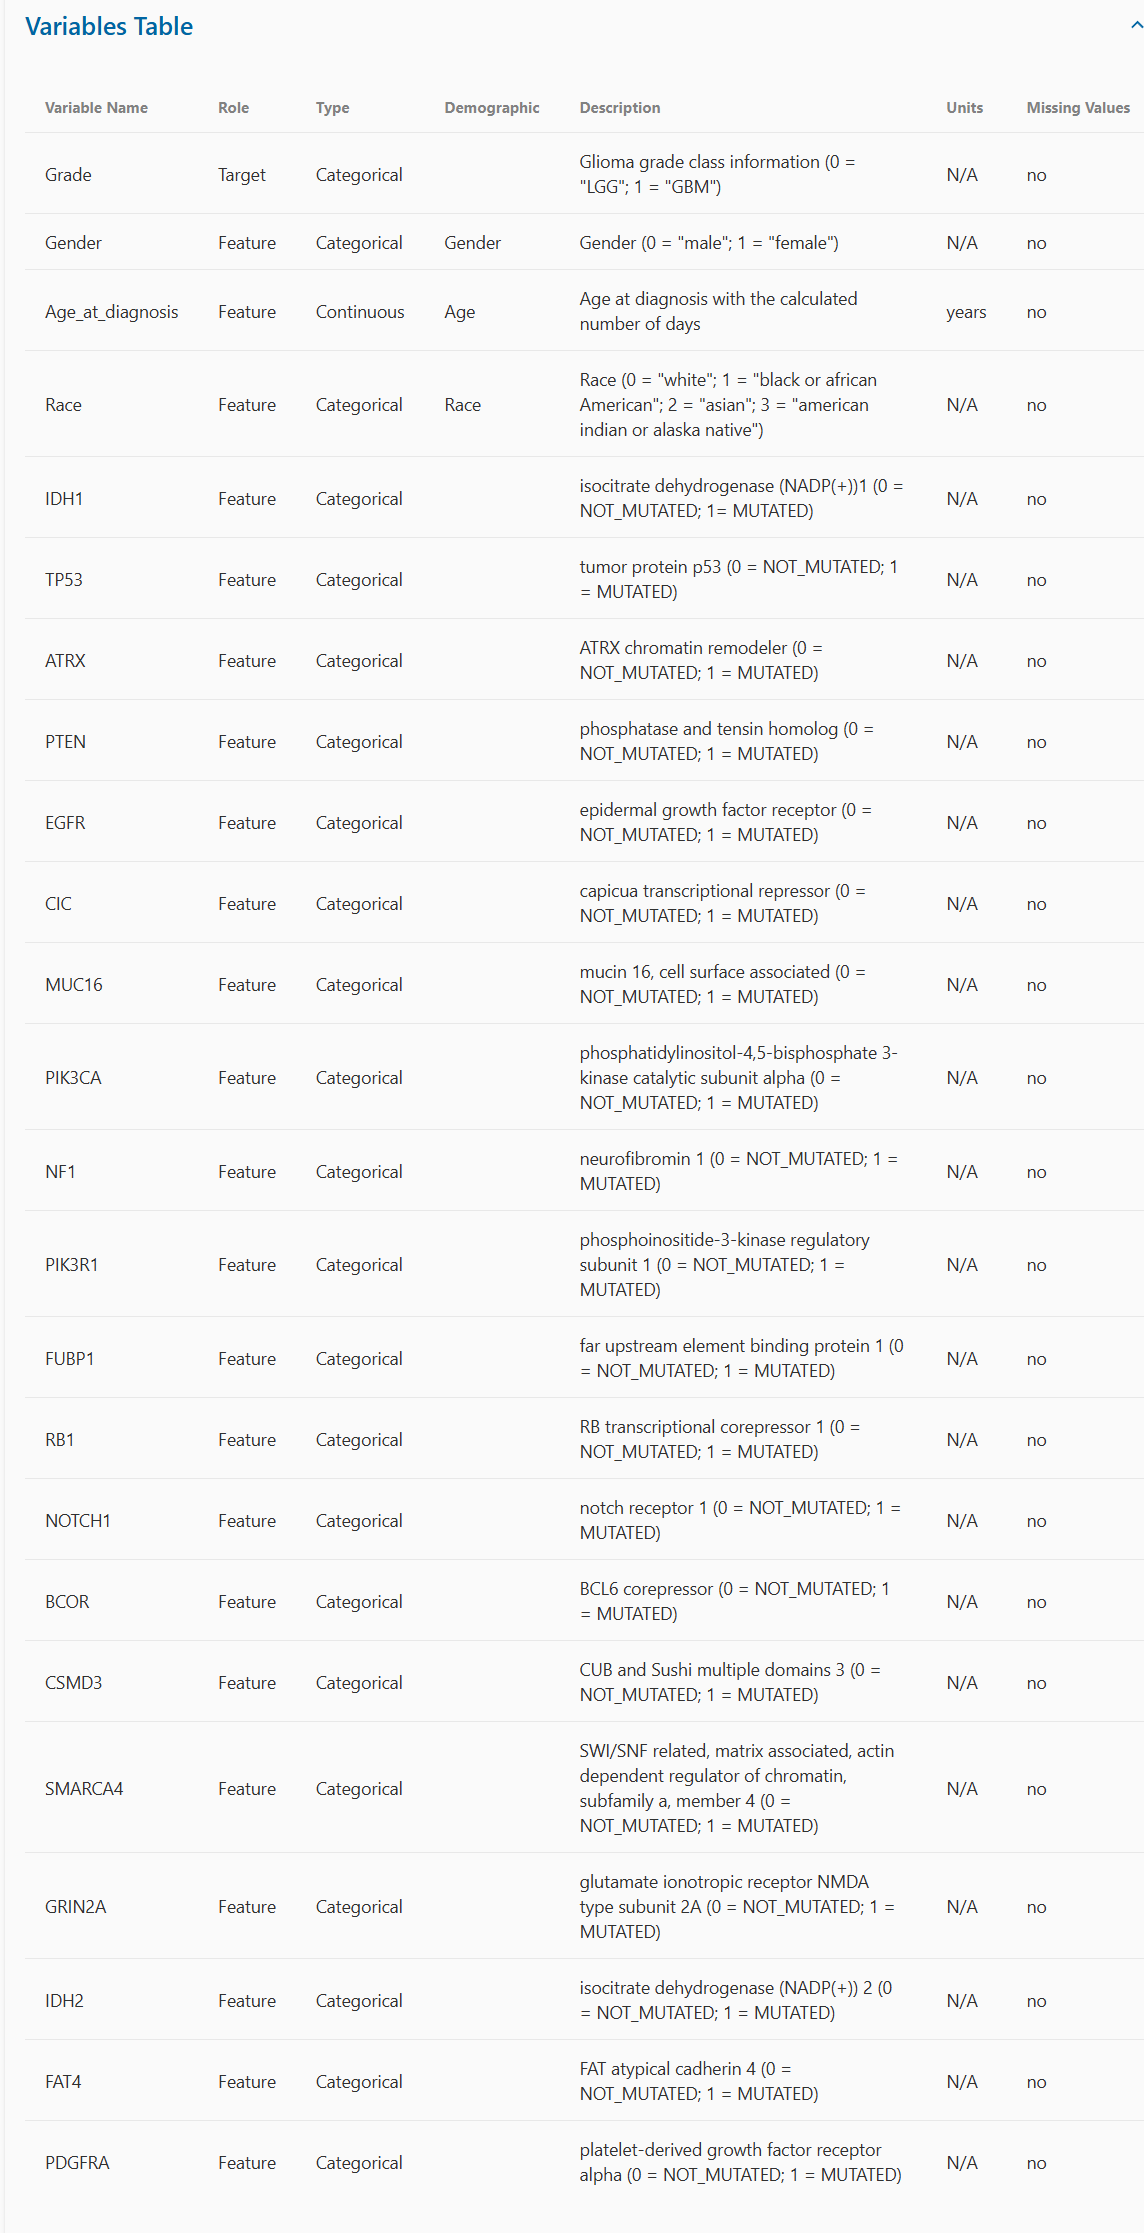

In [8]:
image = Image.open('./images/3_glioma_grading_clinical_and_mutation_features_variables_table.png')
display(image)

In [9]:
# Head 
display(df.head())

,Grade,Gender,Age_at_diagnosis,Race,IDH1,TP53,ATRX,PTEN,EGFR,CIC,MUC16,PIK3CA,NF1,PIK3R1,FUBP1,RB1,NOTCH1,BCOR,CSMD3,SMARCA4,GRIN2A,IDH2,FAT4,PDGFRA
0,0,0,51.30,0,1,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0
1,0,0,38.72,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,0,0,35.17,0,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,0,1,32.78,0,1,1,1,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,1,0
4,0,0,31.51,0,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [10]:
# Tail 
display(df.tail())

,Grade,Gender,Age_at_diagnosis,Race,IDH1,TP53,ATRX,PTEN,EGFR,CIC,MUC16,PIK3CA,NF1,PIK3R1,FUBP1,RB1,NOTCH1,BCOR,CSMD3,SMARCA4,GRIN2A,IDH2,FAT4,PDGFRA
834,1,1,77.89,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
835,1,0,85.18,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
836,1,1,77.49,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
837,1,0,63.33,0,0,1,0,0,0,0,1,1,0,0,0,1,0,0,0,0,0,0,0,0
838,1,0,76.61,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


### Sanity check of the dataset

In [11]:
# Dataset information
print("Dataframe info:")
df.info()

Dataframe info:
<class 'pandas.DataFrame'>
RangeIndex: 839 entries, 0 to 838
Data columns (total 24 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Grade             839 non-null    int64  
 1   Gender            839 non-null    int64  
 2   Age_at_diagnosis  839 non-null    float64
 3   Race              839 non-null    int64  
 4   IDH1              839 non-null    int64  
 5   TP53              839 non-null    int64  
 6   ATRX              839 non-null    int64  
 7   PTEN              839 non-null    int64  
 8   EGFR              839 non-null    int64  
 9   CIC               839 non-null    int64  
 10  MUC16             839 non-null    int64  
 11  PIK3CA            839 non-null    int64  
 12  NF1               839 non-null    int64  
 13  PIK3R1            839 non-null    int64  
 14  FUBP1             839 non-null    int64  
 15  RB1               839 non-null    int64  
 16  NOTCH1            839 non-null    int64

In [12]:
# Finding missing values
df.isnull().sum()

Grade               0
Gender              0
Age_at_diagnosis    0
Race                0
IDH1                0
TP53                0
ATRX                0
PTEN                0
EGFR                0
CIC                 0
MUC16               0
PIK3CA              0
NF1                 0
PIK3R1              0
FUBP1               0
RB1                 0
NOTCH1              0
BCOR                0
CSMD3               0
SMARCA4             0
GRIN2A              0
IDH2                0
FAT4                0
PDGFRA              0
dtype: int64

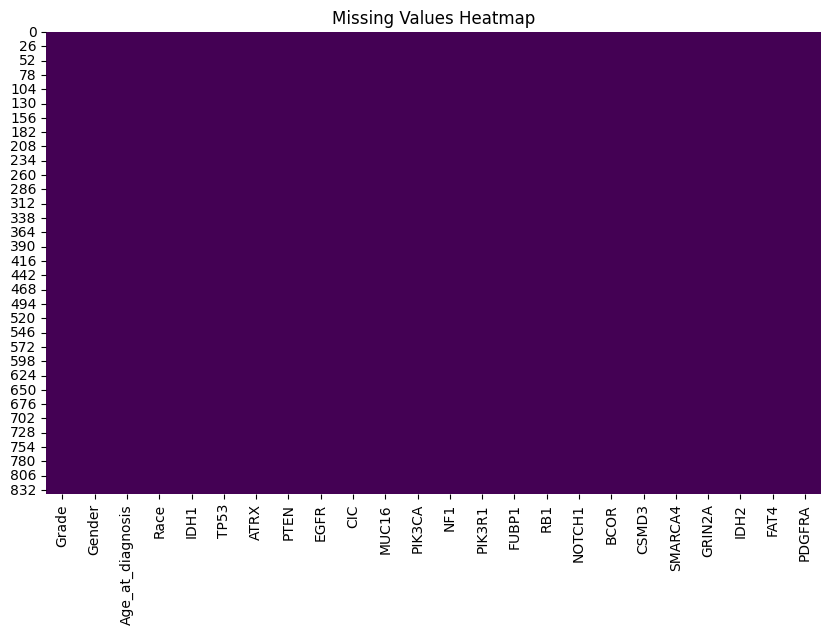

In [13]:
# Missing value visualization
plt.figure(figsize=(10,6))
sns.heatmap(df.isnull(), cbar=False, cmap='viridis')
plt.title('Missing Values Heatmap')
plt.show()

In [14]:
# Finding duplicate values
df.duplicated().sum()

np.int64(1)

# Exploratory Data Analysis (EDA)

In [24]:
LABEL = "Grade"
NUM_FEATS = ["Age_at_diagnosis"]
CAT_FEATS = [col for col in df.columns if col not in NUM_FEATS + [LABEL]]
INP_FEATS = df.drop(LABEL, axis=1).columns.tolist() # original feats

# Descriptive statistics 
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
Grade,839.0,0.419547,0.493779,0.00,0.000,0.00,1.0,1.00
Gender,839.0,0.418355,0.493583,0.00,0.000,0.00,1.0,1.00
Age_at_diagnosis,839.0,50.935411,15.702339,14.42,38.055,51.55,62.8,89.29
Race,839.0,0.107271,0.369392,0.00,0.000,0.00,0.0,3.00
IDH1,839.0,0.481526,0.499957,0.00,0.000,0.00,1.0,1.00
TP53,839.0,0.414779,0.492978,0.00,0.000,0.00,1.0,1.00
ATRX,839.0,0.258641,0.438149,0.00,0.000,0.00,1.0,1.00
PTEN,839.0,0.168057,0.374140,0.00,0.000,0.00,0.0,1.00
EGFR,839.0,0.133492,0.340309,0.00,0.000,0.00,0.0,1.00
CIC,839.0,0.132300,0.339019,0.00,0.000,0.00,0.0,1.00


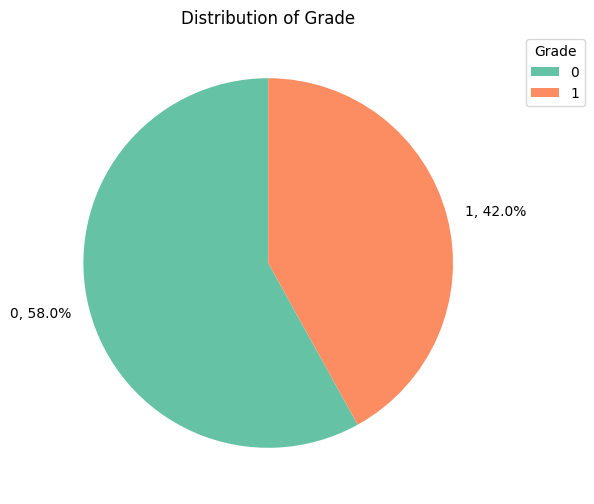

In [25]:
# Counting the observations for each category
status_counts = df[LABEL].value_counts()
labels = status_counts.index
sizes = status_counts.values

# Calculating the percentage of each category
percentages = 100.*sizes/sizes.sum()

# Creating the pie chart with percentages in the labels
plt.figure(figsize=(10, 6))
plt.pie(sizes, labels=[f"{l}, {s:.1f}%" for l, s in zip(labels, percentages)], startangle=90)
plt.gca().set_aspect("equal")
plt.legend(loc="upper right", bbox_to_anchor=(1.2, 1), labels=labels, title=LABEL)
plt.title(f"Distribution of {LABEL}")
plt.show()

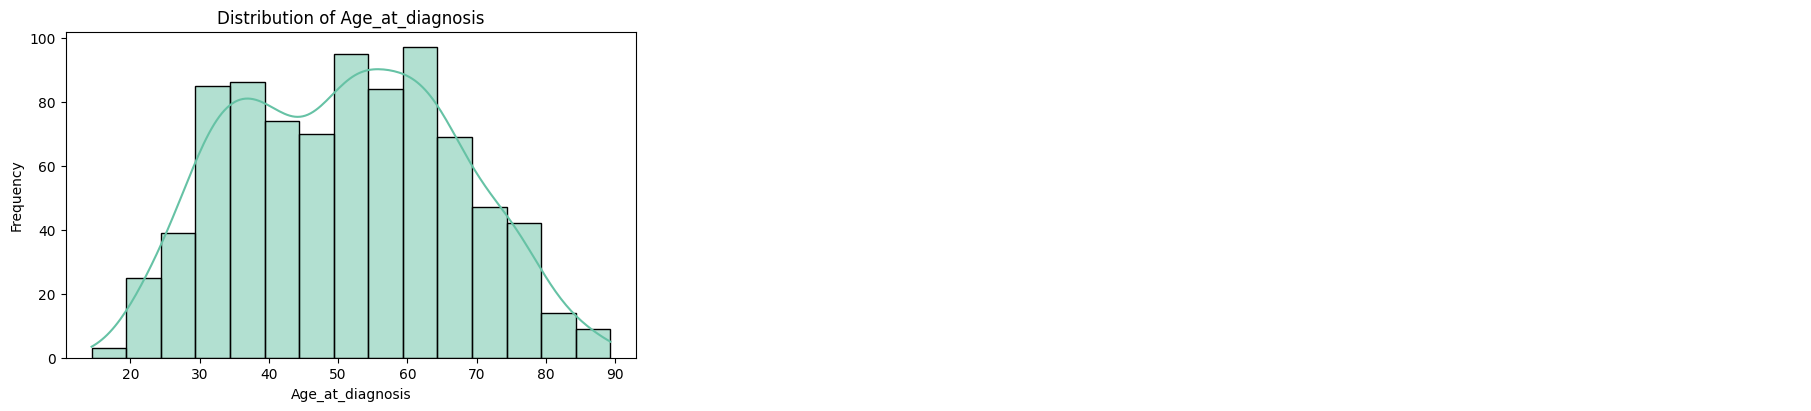

In [27]:
# Histograms to visualize distributions (skip id) [in subplots]

cols = NUM_FEATS
n = len(cols)

# layout
ncols = 3  # change if you want (e.g., 2 or 4)
nrows = math.ceil(n / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(6*ncols, 4*nrows), constrained_layout=True)
axes = np.array(axes).reshape(-1)  # flatten in case it's 2D

for ax, col in zip(axes, cols):
    sns.histplot(df[col].dropna(), kde=True, ax=ax)
    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Frequency")

# turn off any unused axes
for ax in axes[len(cols):]:
    ax.axis("off")

plt.show()

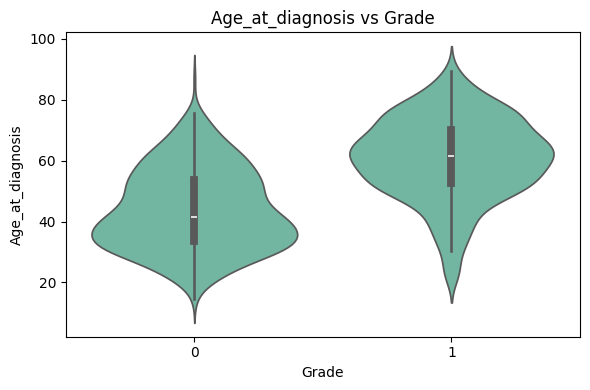

In [ ]:
# violin plots for numerical features 
plt.figure(figsize=(6, 4))
sns.violinplot(x=LABEL, y=NUM_FEATS[0], data=df)
plt.title(f"{NUM_FEATS[0]} vs {LABEL}")
plt.tight_layout()
plt.show()

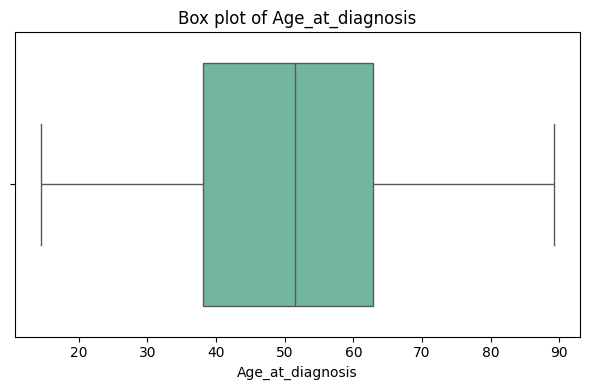

In [31]:
# Boxplot
cols = NUM_FEATS

# single numeric feature case
col = cols[0]

plt.figure(figsize=(6, 4))
sns.boxplot(x=df[col])
plt.title(f"Box plot of {col}")
plt.xlabel(col)
plt.ylabel("")
plt.tight_layout()
plt.show()

In [34]:
# Correlation matrix
def cramers_v(x, y):
    tbl = pd.crosstab(x, y)
    if tbl.size == 0:
        return np.nan
    chi2, _, _, _ = chi2_contingency(tbl, correction=False)
    n = tbl.to_numpy().sum()
    r, k = tbl.shape
    if n == 0:
        return np.nan
    return np.sqrt((chi2 / n) / (min(k - 1, r - 1) if min(k - 1, r - 1) > 0 else np.nan))

cat_cols = CAT_FEATS  # your categorical columns
cv = pd.DataFrame(index=cat_cols, columns=cat_cols, dtype=float)

for a in cat_cols:
    for b in cat_cols:
        cv.loc[a, b] = 1.0 if a == b else cramers_v(df[a], df[b])

cv = cv.astype(float)

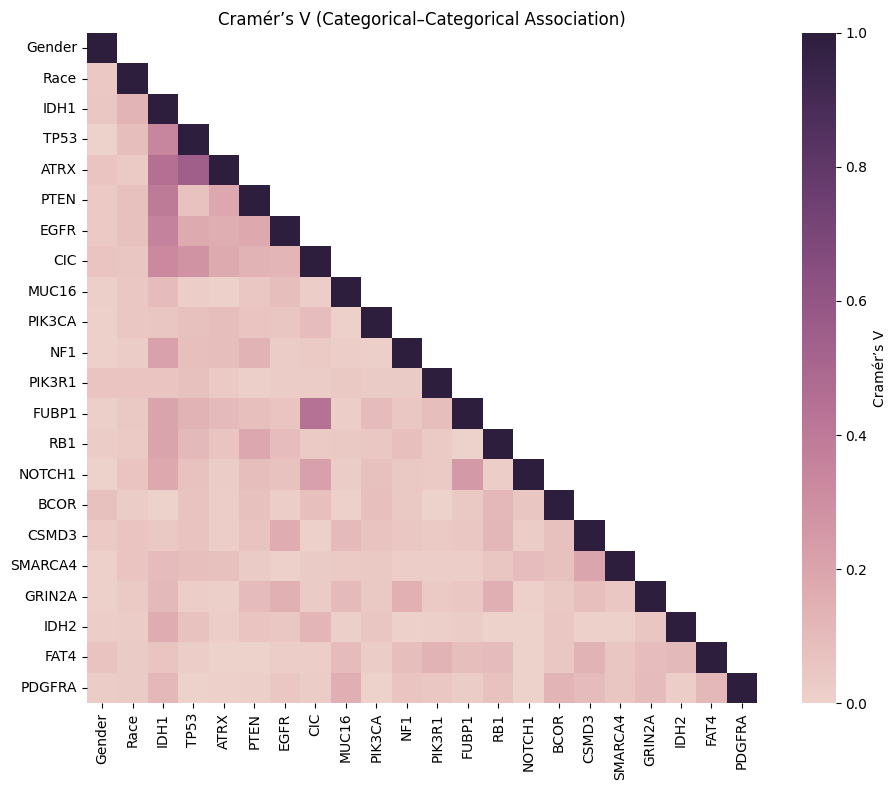

In [36]:
mask = np.triu(np.ones_like(cv, dtype=bool), k=1)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cv,
    mask=mask,          # hide upper triangle     
    vmin=0,
    vmax=1,
    cmap=sns.cubehelix_palette(as_cmap=True),
    square=True,
    cbar_kws={"label": "Cramér’s V"}
)
plt.title("Cramér’s V (Categorical–Categorical Association)")
plt.tight_layout()
plt.show()


# Missing value treatment

In [37]:
# Null count check
df.isnull().sum()

Grade               0
Gender              0
Age_at_diagnosis    0
Race                0
IDH1                0
TP53                0
ATRX                0
PTEN                0
EGFR                0
CIC                 0
MUC16               0
PIK3CA              0
NF1                 0
PIK3R1              0
FUBP1               0
RB1                 0
NOTCH1              0
BCOR                0
CSMD3               0
SMARCA4             0
GRIN2A              0
IDH2                0
FAT4                0
PDGFRA              0
dtype: int64

### No missing values detected, No action needed
## But some duplicate rows detected, removing duplicates

In [38]:
df_dedup = df.drop_duplicates(subset=INP_FEATS, keep="first").reset_index(drop=True)

print("Before:", df.shape, "After:", df_dedup.shape,
      "Removed:", df.shape[0] - df_dedup.shape[0])

Before: (839, 24) After: (838, 24) Removed: 1


In [39]:
df = df_dedup.copy()

# Dataset already encoded appropriately

In [40]:
df.to_csv("./data/preprocessed/3_glioma_grading_clinical_and_mutation_features_preprocessed_df.csv", index=False)

In [41]:
# Lading preprocessed data
df = pd.read_csv("./data/preprocessed/3_glioma_grading_clinical_and_mutation_features_preprocessed_df.csv")

In [43]:
LABEL = "Grade"
NUM_FEATS = ["Age_at_diagnosis"]
CAT_FEATS = [col for col in df.columns if col not in NUM_FEATS + [LABEL]]
INP_FEATS = df.drop(LABEL, axis=1).columns.tolist() # original feats

# Running a base model

In [44]:
# Split features/label
X = df.drop(columns=[LABEL])   # LABEL = "Status"
y = df[LABEL]

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y  # keeps class proportions similar in train/test
)

In [ ]:
model = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(max_iter=5000))
])

# start timer
start_time = time.perf_counter()

# training
model.fit(X_train, y_train)

# end timer
train_time = time.perf_counter() - start_time

y_pred = model.predict(X_test)
acc = accuracy_score(y_test, y_pred)
print("Accuracy: {:.4f} %".format(acc))
print(f"Training time: {train_time:.6f} seconds")

Accuracy: 0.8631 %
